# Milestone 3 - Masked-token encoder

Predict hidden or damaged signs from context, with calibrated confidence. This notebook shows the learning curves (token-prediction loss), the model search, the held-out results, **5-fold cross-validation** and calibration.

*Regenerate:* `cd src/m3_masking && python run_all.py` (search + 3 seeds) and `python src/m3_masking/cv.py`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in ("src", "src/m3_masking", "src/m4_guardrails", "src/m2_markov", "src/m1_vision"):
    sys.path.insert(0, str(ROOT / p))
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

## 1. Learning curves: token-prediction loss, 3 seeds
Training loss is the masked-sign cross-entropy; validation is leave-one-out NLL on the validation split.

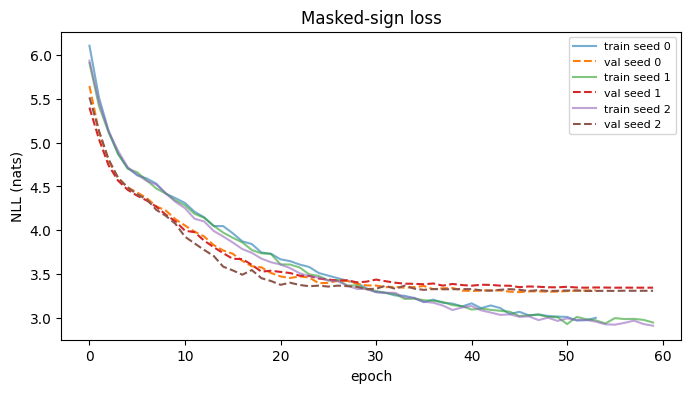

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for s in range(3):
    h = json.load(open(ROOT / f"src/m3_masking/artifacts/history_seed{s}.json"))
    ax.plot([x[1] for x in h], alpha=.6, label=f"train seed {s}"); ax.plot([x[2] for x in h], "--", label=f"val seed {s}")
ax.set(xlabel="epoch", ylabel="NLL (nats)", title="Masked-sign loss"); ax.legend(fontsize=8); plt.show()

## 2. Model search (one seed per configuration, validation NLL)

In [3]:
display(pd.DataFrame([{**r["cfg"], "val_nll": r["val_nll"], "epochs": r["epochs"]} for r in json.load(open(ROOT / "src/m3_masking/artifacts/search.json"))]).sort_values("val_nll"))

,d,layers,heads,ff,dropout,val_nll,epochs
1,64,2,4,128,0.2,3.2937,54
4,128,2,4,256,0.3,3.3720,33
3,128,2,4,256,0.2,3.4027,30
2,128,1,4,256,0.2,3.4235,32
0,64,1,4,128,0.1,3.4688,34


## 3. Held-out test split (350 inscriptions, 1,304 hidden signs)

In [4]:
res = json.load(open(ROOT / "src/m3_masking/artifacts/results.json"))
L = res["protocols"]["loo"]; f = lambda v: v[0] if isinstance(v, list) else v
display(pd.DataFrame({k: {m: round(f(v[m]), 4) for m in ("top1", "top3", "top5", "ppl", "ece")} for k, v in L.items()}).T)

,top1,top3,top5,ppl,ece
Unigram (frequency),0.1097,0.1902,0.2439,111.9495,0.0124
Witten-Bell bigram (bidirectional),0.3351,0.4962,0.5629,31.2325,0.0283
"Transformer (single seed, mean±std)",0.3269,0.4847,0.5493,32.1186,0.0846
Transformer ensemble (uncalibrated),0.3336,0.5038,0.5698,27.2584,0.0644
Transformer ensemble (calibrated),0.3336,0.5038,0.5698,26.1031,0.0354


## 4. Five-fold cross-validation (all 3,491 unique sequences, 12,525 predictions)

In [5]:
cv = json.load(open(ROOT / "reports/m3/cv.json")); m = cv["metrics"]; e = cv["ensemble_cv"]
rows = [dict(model=k, top1=f"{100*m[k]['top1']['mean']:.1f}% ± {100*m[k]['top1']['sd']:.1f}", top5=f"{100*m[k]['top5']['mean']:.1f}% ± {100*m[k]['top5']['sd']:.1f}",
             perplexity=f"{m[k]['ppl']['mean']:.1f} ± {m[k]['ppl']['sd']:.1f}") for k in ("unigram", "bigram", "transformer")]
ens5 = [f_["ensemble"]["top5"] for f_ in e["per_fold"]]
rows.append(dict(model="ensemble of 3 (deliverable)", top1=f"{100*e['ensemble_top1']['mean']:.1f}% ± {100*e['ensemble_top1']['sd']:.1f}",
                 top5=f"{100*np.mean(ens5):.1f}% ± {100*np.std(ens5, ddof=1):.1f}", perplexity=f"{e['ensemble_ppl']['mean']:.1f} ± {e['ensemble_ppl']['sd']:.1f}"))
display(pd.DataFrame(rows)); p = e["pooled"]
print(f"ensemble vs bigram, pooled: {p['only_ensemble_right']} vs {p['only_bigram_right']} disagreements, McNemar p = {p['mcnemar_p']:.3f}; "
      f"perplexity gap {p['ppl_gap_bigram_minus_ensemble']:.2f} (95% CI {p['ppl_gap_ci95'][0]:.2f}-{p['ppl_gap_ci95'][1]:.2f}); folds won: top-1 {e['folds_ensemble_better_top1']}/5, perplexity {e['folds_ensemble_better_ppl']}/5")

,model,top1,top5,perplexity
0,unigram,10.3% ± 0.3,24.1% ± 0.6,112.0 ± 3.8
1,bigram,32.5% ± 1.2,55.2% ± 0.9,31.8 ± 1.0
2,transformer,32.2% ± 0.8,54.1% ± 0.7,32.1 ± 1.0
3,ensemble of 3 (deliverable),33.3% ± 0.6,55.7% ± 0.4,28.8 ± 0.5


ensemble vs bigram, pooled: 761 vs 660 disagreements, McNemar p = 0.008; perplexity gap 2.98 (95% CI 2.29-3.65); folds won: top-1 4/5, perplexity 5/5


**Reading:** a single Transformer is no better than the Witten–Bell bigram. The ensemble of three beats it by a small, consistent margin.

## 5. Calibration and confidence bands

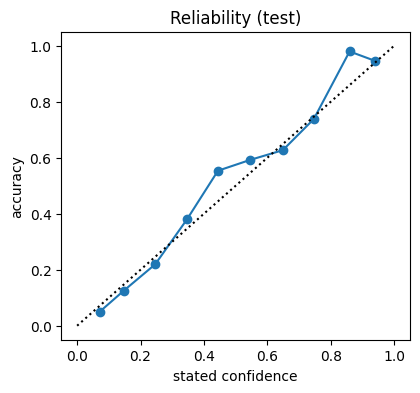

,n,accuracy,mean_conf
High,294.0,0.751701,0.724341
Medium,459.0,0.350763,0.325701
Low,551.0,0.096189,0.117884


In [6]:
t = res["ece_table_calibrated"]
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.plot([r[3] for r in t], [r[4] for r in t], "o-"); ax.plot([0, 1], [0, 1], "k:")
ax.set(xlabel="stated confidence", ylabel="accuracy", title="Reliability (test)"); plt.show()
display(pd.DataFrame(res["confidence_bands_test"]).T)

## 6. Using the model (`predict.py`), including Milestone 1-style input

In [7]:
from predict import SignCompleter
sc = SignCompleter()
for args in (("+740-000-590+", {}), (["P385", "?", "P324"], dict(numbering="parpola", order="reading"))):
    r = sc.complete(args[0], top_k=3, **args[1])
    print(r["completed_in_input_numbering_and_order"], "|", [(c["sign_in_input_numbering"], round(c["prob"], 2)) for c in r["gaps"][0]["candidates"]], r["gaps"][0]["rating"])

740 390 590 | [('390', 0.63), ('405', 0.16), ('407', 0.04)] High
P385 P122 P324 | [('P122', 0.19), ('P332', 0.09), ('P075', 0.04)] Low
